In [1]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [8]:
# Import the libraries required for data analysis and visualisation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# Load the raw CSV files into Pandas DataFrames

sessions = pd.read_csv(r"C:\Users\reeya\OneDrive\문서\Project_1_Cart_Abandonment\Data\Raw\website_sessions.csv")
pageviews = pd.read_csv(r"C:\Users\reeya\OneDrive\문서\Project_1_Cart_Abandonment\Data\Raw\website_pageviews.csv")
orders = pd.read_csv(r"C:\Users\reeya\OneDrive\문서\Project_1_Cart_Abandonment\Data\Raw\orders.csv")

In [ ]:
# Display the number of rows and columns in each dataset

print("website_sessions:", sessions.shape)
print("website_pageviews:", pageviews.shape)
print("orders:", orders.shape)

website_sessions: (472871, 9)
website_pageviews: (1188124, 4)
orders: (32313, 8)


In [8]:
# Display the first five records from each dataset
print("website_sessions")
display(sessions.head())

print("website_pageviews")
display(pageviews.head())

print("orders")
display(orders.head())

website_sessions


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


website_pageviews


,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home


orders


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


In [10]:
# Inspect the structure, column names, data types and non-null values
# in the website sessions dataset
sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   website_session_id  472871 non-null  int64 
 1   created_at          472871 non-null  object
 2   user_id             472871 non-null  int64 
 3   is_repeat_session   472871 non-null  int64 
 4   utm_source          389543 non-null  object
 5   utm_campaign        389543 non-null  object
 6   utm_content         389543 non-null  object
 7   device_type         472871 non-null  object
 8   http_referer        432954 non-null  object
dtypes: int64(3), object(6)
memory usage: 32.5+ MB


In [11]:
# Inspect the structure, column names, data types and non-null values
# in the website pageviews dataset
pageviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1188124 entries, 0 to 1188123
Data columns (total 4 columns):
 #   Column               Non-Null Count    Dtype 
---  ------               --------------    ----- 
 0   website_pageview_id  1188124 non-null  int64 
 1   created_at           1188124 non-null  object
 2   website_session_id   1188124 non-null  int64 
 3   pageview_url         1188124 non-null  object
dtypes: int64(2), object(2)
memory usage: 36.3+ MB


In [12]:
# Inspect the structure, column names, data types and non-null values
# in the orders dataset
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  object 
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 2.0+ MB


In [13]:
# Convert the created_at columns into datetime format
# This enables accurate date and time-based analysis

sessions["created_at"] = pd.to_datetime(
    sessions["created_at"], errors="coerce"
)

pageviews["created_at"] = pd.to_datetime(
    pageviews["created_at"], errors="coerce"
)

orders["created_at"] = pd.to_datetime(
    orders["created_at"], errors="coerce"
)

In [14]:
# Verify the data type of each converted date column
print("Website Sessions:", sessions["created_at"].dtype)
print("Website Pageviews:", pageviews["created_at"].dtype)
print("Orders:", orders["created_at"].dtype)

# Count invalid date values produced during conversion
print("\nInvalid Dates:")
print("Website Sessions:", sessions["created_at"].isna().sum())
print("Website Pageviews:", pageviews["created_at"].isna().sum())
print("Orders:", orders["created_at"].isna().sum())

Website Sessions: datetime64[ns]
Website Pageviews: datetime64[ns]
Orders: datetime64[ns]

Invalid Dates:
Website Sessions: 0
Website Pageviews: 0
Orders: 0


In [15]:
# Check whether any entire records are duplicated
print("Duplicate Rows:")
print("Website Sessions:", sessions.duplicated().sum())
print("Website Pageviews:", pageviews.duplicated().sum())
print("Orders:", orders.duplicated().sum())

Duplicate Rows:
Website Sessions: 0
Website Pageviews: 0
Orders: 0


In [16]:
# Check whether primary ID columns contain duplicate values
print("Duplicate IDs:")
print("Website Sessions:", sessions["website_session_id"].duplicated().sum())
print("Website Pageviews:", pageviews["website_pageview_id"].duplicated().sum())
print("Orders:", orders["order_id"].duplicated().sum())

Duplicate IDs:
Website Sessions: 0
Website Pageviews: 0
Orders: 0


In [17]:
# Identify pageview session IDs that do not exist in the sessions dataset

unmatched_pageviews = pageviews[
    ~pageviews["website_session_id"].isin(
        sessions["website_session_id"]
    )
]

# Count unmatched pageview records and distinct session IDs
print("Unmatched Pageview Records:", len(unmatched_pageviews))
print(
    "Unmatched Pageview Sessions:",
    unmatched_pageviews["website_session_id"].nunique()
)

Unmatched Pageview Records: 0
Unmatched Pageview Sessions: 0


In [18]:
# Identify order session IDs that do not exist in the sessions dataset

unmatched_orders = orders[
    ~orders["website_session_id"].isin(
        sessions["website_session_id"]
    )
]

# Count unmatched order records and distinct session IDs
print("Unmatched Order Records:", len(unmatched_orders))
print(
    "Unmatched Order Sessions:",
    unmatched_orders["website_session_id"].nunique()
)

Unmatched Order Records: 0
Unmatched Order Sessions: 0


In [11]:
# Check missing values in Website Sessions

print("Missing Values:")
print(sessions.isnull().sum())

print("\nMissing Value Percentage:")
print((sessions.isnull().mean() * 100).round(2))

Missing Values:
website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917
dtype: int64

Missing Value Percentage:
website_session_id     0.00
created_at             0.00
user_id                0.00
is_repeat_session      0.00
utm_source            17.62
utm_campaign          17.62
utm_content           17.62
device_type            0.00
http_referer           8.44
dtype: float64


In [12]:
# Check missing values in Website Pageviews

print("Missing Values:")
print(pageviews.isnull().sum())

print("\nMissing Value Percentage:")
print((pageviews.isnull().mean() * 100).round(2))

Missing Values:
website_pageview_id    0
created_at             0
website_session_id     0
pageview_url           0
dtype: int64

Missing Value Percentage:
website_pageview_id    0.0
created_at             0.0
website_session_id     0.0
pageview_url           0.0
dtype: float64


In [13]:
# Check missing values in Orders

print("Missing Values:")
print(orders.isnull().sum())

print("\nMissing Value Percentage:")
print((orders.isnull().mean() * 100).round(2))

Missing Values:
order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

Missing Value Percentage:
order_id              0.0
created_at            0.0
website_session_id    0.0
user_id               0.0
primary_product_id    0.0
items_purchased       0.0
price_usd             0.0
cogs_usd              0.0
dtype: float64


In [14]:
# Check the number of records for each pageview URL

print(pageviews["pageview_url"].value_counts())

pageview_url
/products                      261231
/the-original-mr-fuzzy         162525
/home                          137576
/lander-2                      131170
/cart                           94953
/lander-3                       79000
/lander-5                       68166
/shipping                       64484
/billing-2                      48441
/lander-1                       47574
/thank-you-for-your-order       32313
/the-forever-love-bear          26033
/the-birthday-sugar-panda       19046
/lander-4                        9385
/billing                         3617
/the-hudson-river-mini-bear      2610
Name: count, dtype: int64


In [15]:
# Check the number of sessions by device type

print(sessions["device_type"].value_counts())

device_type
desktop    327027
mobile     145844
Name: count, dtype: int64


In [16]:
# Check date ranges in all three datasets

print("Website Sessions:")
print(sessions["created_at"].min(), "to", sessions["created_at"].max())

print("\nWebsite Pageviews:")
print(pageviews["created_at"].min(), "to", pageviews["created_at"].max())

print("\nOrders:")
print(orders["created_at"].min(), "to", orders["created_at"].max())

Website Sessions:
2012-03-19 08:04:16 to 2015-03-19 07:59:08

Website Pageviews:
2012-03-19 08:04:16 to 2015-03-19 07:59:32

Orders:
2012-03-19 10:42:46 to 2015-03-19 05:38:31


In [17]:
# Select the four checkout funnel stages

funnel_pages = [
    "/products",
    "/cart",
    "/shipping",
    "/thank-you-for-your-order"
]

funnel_data = pageviews[
    pageviews["pageview_url"].isin(funnel_pages)
].copy()

print(funnel_data["pageview_url"].value_counts())

pageview_url
/products                    261231
/cart                         94953
/shipping                     64484
/thank-you-for-your-order     32313
Name: count, dtype: int64


In [18]:
# Count unique sessions at each funnel stage

funnel_sessions = (
    funnel_data.groupby("pageview_url")["website_session_id"]
    .nunique()
)

print(funnel_sessions)

pageview_url
/cart                         94953
/products                    261231
/shipping                     64484
/thank-you-for-your-order     32313
Name: website_session_id, dtype: int64


In [19]:
# Find the first timestamp for each funnel stage per session

funnel_order = (
    funnel_data
    .sort_values("created_at")
    .groupby(["website_session_id", "pageview_url"])["created_at"]
    .min()
    .unstack()
)

print(funnel_order.head())

pageview_url                      /cart            /products  \
website_session_id                                             
6                   2012-03-19 09:14:02  2012-03-19 09:10:08   
15                                  NaN  2012-03-19 10:01:46   
16                                  NaN  2012-03-19 10:07:07   
18                  2012-03-19 10:23:23  2012-03-19 10:18:58   
20                  2012-03-19 10:31:29  2012-03-19 10:28:09   

pageview_url                  /shipping /thank-you-for-your-order  
website_session_id                                                 
6                   2012-03-19 09:16:52                       NaN  
15                                  NaN                       NaN  
16                                  NaN                       NaN  
18                                  NaN                       NaN  
20                  2012-03-19 10:34:43       2012-03-19 10:42:46  


In [20]:
# Identify sessions progressing through the funnel in order

product = funnel_order["/products"]
cart = funnel_order["/cart"]
shipping = funnel_order["/shipping"]
purchase = funnel_order["/thank-you-for-your-order"]

product_sessions = product.notna()

cart_sessions = (
    product_sessions &
    cart.notna() &
    (cart > product)
)

shipping_sessions = (
    cart_sessions &
    shipping.notna() &
    (shipping > cart)
)

purchase_sessions = (
    shipping_sessions &
    purchase.notna() &
    (purchase > shipping)
)

print("Product Sessions:", product_sessions.sum())
print("Cart Sessions:", cart_sessions.sum())
print("Shipping Sessions:", shipping_sessions.sum())
print("Purchase Sessions:", purchase_sessions.sum())

Product Sessions: 261231
Cart Sessions: 94953
Shipping Sessions: 64484
Purchase Sessions: 32313


In [21]:
# Create funnel summary

funnel_summary = pd.DataFrame({
    "Stage": ["Product", "Cart", "Shipping", "Purchase"],
    "Sessions": [
        product_sessions.sum(),
        cart_sessions.sum(),
        shipping_sessions.sum(),
        purchase_sessions.sum()
    ]
})

# Calculate conversion and drop-off rates

funnel_summary["Conversion Rate (%)"] = (
    funnel_summary["Sessions"] /
    funnel_summary["Sessions"].shift(1) * 100
)

funnel_summary["Drop-off (%)"] = (
    100 - funnel_summary["Conversion Rate (%)"]
)

# Set initial funnel stage values

funnel_summary.loc[0, "Conversion Rate (%)"] = 100
funnel_summary.loc[0, "Drop-off (%)"] = 0

print(funnel_summary.round(2))

      Stage  Sessions  Conversion Rate (%)  Drop-off (%)
0   Product    261231               100.00          0.00
1      Cart     94953                36.35         63.65
2  Shipping     64484                67.91         32.09
3  Purchase     32313                50.11         49.89


In [22]:
# Add device type to the reconstructed funnel data

device_funnel = funnel_order.join(
    sessions.set_index("website_session_id")["device_type"]
)

# Check session distribution by device

print(device_funnel["device_type"].value_counts())

device_type
desktop    192325
mobile      68906
Name: count, dtype: int64


In [23]:
# Calculate funnel metrics separately for each device

device_results = []

for device, data in device_funnel.groupby("device_type"):

    product = data["/products"]
    cart = data["/cart"]
    shipping = data["/shipping"]
    purchase = data["/thank-you-for-your-order"]

    product_count = product.notna()

    cart_count = (
        product_count & cart.notna() & (cart > product)
    )

    shipping_count = (
        cart_count & shipping.notna() & (shipping > cart)
    )

    purchase_count = (
        shipping_count & purchase.notna() & (purchase > shipping)
    )

    counts = [
        product_count.sum(),
        cart_count.sum(),
        shipping_count.sum(),
        purchase_count.sum()
    ]

    for i, stage in enumerate(
        ["Product", "Cart", "Shipping", "Purchase"]
    ):
        conversion = (
            counts[i] / counts[i-1] * 100 if i > 0 else 100
        )

        device_results.append({
            "Device": device,
            "Stage": stage,
            "Sessions": counts[i],
            "Conversion Rate (%)": conversion,
            "Drop-off (%)": 100 - conversion
        })

device_summary = pd.DataFrame(device_results)

print(device_summary.round(2))

    Device     Stage  Sessions  Conversion Rate (%)  Drop-off (%)
0  desktop   Product    192325               100.00          0.00
1  desktop      Cart     75155                39.08         60.92
2  desktop  Shipping     52692                70.11         29.89
3  desktop  Purchase     27805                52.77         47.23
4   mobile   Product     68906               100.00          0.00
5   mobile      Cart     19798                28.73         71.27
6   mobile  Shipping     11792                59.56         40.44
7   mobile  Purchase      4508                38.23         61.77


In [24]:

confirmation_sessions = set(
    funnel_order.loc[
        funnel_order["/thank-you-for-your-order"].notna()
    ].index
)

order_sessions = set(orders["website_session_id"])


In [25]:

confirmation_with_orders = confirmation_sessions & order_sessions

confirmation_without_orders = confirmation_sessions - order_sessions

orders_without_confirmation = order_sessions - confirmation_sessions

print("Confirmation Sessions:", len(confirmation_sessions))
print("Confirmation Sessions With Orders:", len(confirmation_with_orders))
print("Confirmation Sessions Without Orders:", len(confirmation_without_orders))
print("Orders Without Confirmation Page:", len(orders_without_confirmation))


Confirmation Sessions: 32313
Confirmation Sessions With Orders: 32313
Confirmation Sessions Without Orders: 0
Orders Without Confirmation Page: 0


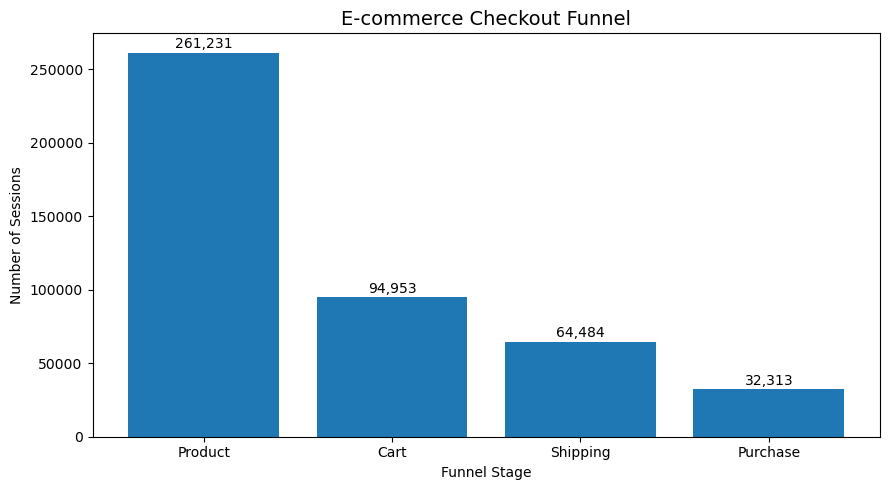

In [26]:

import matplotlib.pyplot as plt

stages = ["Product", "Cart", "Shipping", "Purchase"]
sessions = [261231, 94953, 64484, 32313]

plt.figure(figsize=(9, 5))

bars = plt.bar(stages, sessions)

plt.title("E-commerce Checkout Funnel", fontsize=14)
plt.xlabel("Funnel Stage")
plt.ylabel("Number of Sessions")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 3000,
        f"{int(value):,}",
        ha="center"
    )

plt.tight_layout()
plt.show()


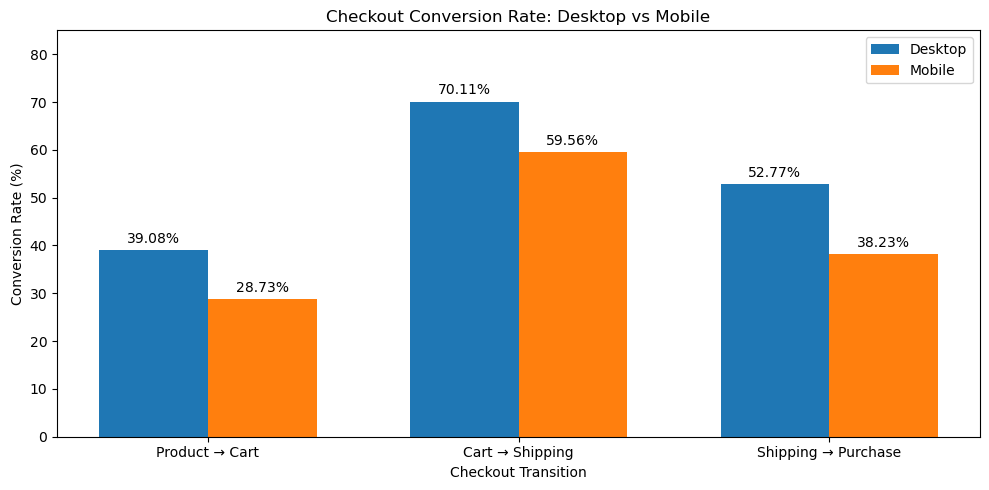

In [27]:
import matplotlib.pyplot as plt
import numpy as np

transitions = [
    "Product → Cart",
    "Cart → Shipping",
    "Shipping → Purchase"
]

desktop = [39.08, 70.11, 52.77]
mobile = [28.73, 59.56, 38.23]

x = np.arange(len(transitions))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(x - width/2, desktop, width, label="Desktop")
bars2 = ax.bar(x + width/2, mobile, width, label="Mobile")

ax.set_title("Checkout Conversion Rate: Desktop vs Mobile")
ax.set_xlabel("Checkout Transition")
ax.set_ylabel("Conversion Rate (%)")

ax.set_xticks(x)
ax.set_xticklabels(transitions)

ax.set_ylim(0, 85)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()